---
## Fitting FBK data ##
---
#### Imports

Importing and calling ...../Fitting/GenPaths.py
added to path: ['/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/Fitting', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling']
PROPATH variable: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


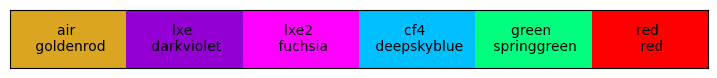

In [2]:
from GenPaths import * # this provides PROPATH which helps load stuff (and the paths to find the PDEhelpers stuff)

import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter1d
import time

from scipy import optimize as opt
from scipy import stats as sps
import iminuit
from iminuit import Minuit

from PDEhelpers.OpticsDataLoader import *
import PDEhelpers.MathEquations as ME
from PDEhelpers.PhotonInfo import * # this calls DataLoader when defining init
# from PDEhelpers.PNJunction import *
import PDEhelpers.PNJunction as PNJ

import PDE_fittingTools as SS

import PDEhelpers.PDEStyle as MS
MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option


In [3]:
######## High level Fitting Functions ########
def PDE_allArgs(wlen, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph, smoothSigma=None, quantum = False, dh = None):
    # to use later
    if smoothSigma is not None:
        theseArgsDict = locals()
        del theseArgsDict["wlen"]
        theseArgsDict["smoothSigma"] = None

    photon = PhotonInfo(wlen, theta1, dataHelper=dh)    
    Ttotal = photon.Wave_TotalTransmission(tOxide) ### XX IMPORTANT TO USE THIS ONE
    # Ttotal = photon.Wave_TotalTransmission(tOxide)
    pn = PNJ.PNJunction(tOxide = tOxide, dp_star = dp_star, Xpn = Xpn, dw_star=dw_star, pe = pe, ph = ph)
    Wp, Wn = pn.calcW_both(photon)
    
    if quantum:
        cutinWl = 380
        nyield = np.where(wlen < cutinWl, np.sqrt(cutinWl/wlen), 1)
        pe = 1-(1-pe)**nyield
    PDE = FF * Ttotal * (Wp*pe + Wn*ph)
    
    if smoothSigma is not None: # expensive but simple/works/robust
        NperSigma = 5
        stepSize = smoothSigma / NperSigma
        NsigmaPast = 3
        newXVals = np.arange(min(wlen)-NsigmaPast*smoothSigma, max(wlen) + NsigmaPast*smoothSigma + stepSize, stepSize) # for full array at once. requires interp1d below
        fullerPDEVals = PDE_allArgs(wlen=newXVals, **theseArgsDict) # WASN'T RECURSIVELY PASSING dh BEFORE
        fullerPDEVals = gaussian_filter1d(fullerPDEVals, sigma=NperSigma) # this sigma argument is saying 'how many X points correspond to 1sigma'
        pdeInt = interp1d(newXVals, fullerPDEVals, kind='linear', fill_value=0)
        return pdeInt(wlen)     
        
    return PDE

-----------------------------
Silicon data from
   ../opticsData/GoodMerged/silicon_crystalline_lithoAndSchinke_merged.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
----

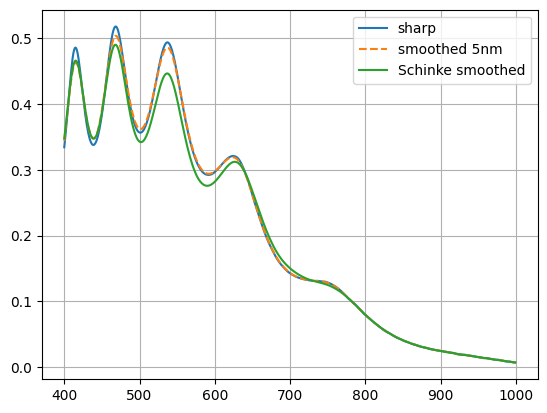

In [4]:
# plotting PDE if probabilities were 1 (for Wp, Wn)
dhSchinke = OpticsData(siDataPath="../opticsData/GoodMerged/silicon_crystalline_lithoAndSchinke_merged.txt")
dhAspnes = OpticsData()

print("--------------- xx ------------")
print(dhSchinke.mPathSi)
print(dhAspnes.mPathSi)

xVals = np.arange(400, 1000, 1)

yPDE_P_aspnes_sharp = PDE_allArgs(xVals, theta1=0, FF=0.6, tOxide=1200, dp_star=2.5, Xpn=2e3, dw_star=10e3, pe=1, ph=0, smoothSigma=None, quantum = False, dh = dhAspnes)
yPDE_P_aspnes_smooth = PDE_allArgs(xVals, theta1=0, FF=0.6, tOxide=1200, dp_star=2.5, Xpn=2e3, dw_star=10e3, pe=1, ph=0, smoothSigma=5, quantum = False, dh = dhAspnes)
yPDE_P_Schinke_sharp = PDE_allArgs(xVals, theta1=0, FF=0.6, tOxide=1200, dp_star=2.5, Xpn=2e3, dw_star=10e3, pe=1, ph=0, smoothSigma=5, quantum = False, dh = dhSchinke)

plt.plot(xVals, yPDE_P_aspnes_sharp, linestyle="-", label='sharp')
plt.plot(xVals, yPDE_P_aspnes_smooth, linestyle="--", label='smoothed 5nm')
plt.plot(xVals, yPDE_P_Schinke_sharp, linestyle="-", label='Schinke smoothed')

# plt.xlim(200, 450)
plt.legend()
plt.grid()
plt.show()

---
### Loading Data

In [5]:
print("---- Low Res Data ----")
file_path = os.path.join(PROPATH, "../veraData/FBK_IR_PDE_LowRes_stat_error_only_April18.csv")
df = pd.read_csv(file_path, header=0)

# print(df)
# print(df.info())
print(df.tail())
print("--------------------------")

print(df['Overvoltage'].value_counts())
print(df['Angle'].value_counts())
print("Voltages:", df['Overvoltage'].unique())
print("Angles:", df['Angle'].unique())
# print(df['Wavelength'].unique())

data_angles = df['Angle'].unique()
data_voltages = df['Overvoltage'].unique()

# print("Angles:", data_angles)
# print("voltages:", data_voltages)

# df = df[(df['Wavelength'] != 399.975) & ((df['Wavelength'] < 695) | (df['Wavelength'] > 705))]

---- Low Res Data ----
     Wavelength  Angle  Overvoltage  Responsivity       PDE      PDE_error
387     790.012      0            8  2.830000e-13  0.075662  6.918510e-310
388     799.979      0            8  2.470000e-13  0.066172  6.918510e-310
389     809.978      0            8  2.220000e-13  0.059495  6.918510e-310
390     820.008      0            8  2.220000e-13  0.059251  6.918510e-310
391     830.012      0            8  2.140000e-13  0.057313  6.918510e-310
--------------------------
Overvoltage
1    49
2    49
3    49
4    49
5    49
6    49
7    49
8    49
Name: count, dtype: int64
Angle
0    392
Name: count, dtype: int64
Voltages: [1 2 3 4 5 6 7 8]
Angles: [0]


In [6]:
print("---- High Res Data ----")

file_pathHR = os.path.join(PROPATH, "../veraData/FBK_IR_PDE_HR_may6.csv")
dfHR = pd.read_csv(file_pathHR, header=0)
print(dfHR.tail())


data_anglesHR = dfHR['Angle'].unique()
data_voltagesHR = dfHR['Overvoltage'].unique()

print("voltages:", data_voltagesHR)
print("angles:", data_anglesHR)
print("wlen range:", dfHR['Wavelength'].min(), dfHR['Wavelength'].max())

---- High Res Data ----
     Wavelength  Angle  Overvoltage  Responsivity       PDE  PDE_error
395     488.010      0            8  1.317970e-12  0.346423   0.000507
396     490.961      0            8  1.259270e-12  0.330992   0.007925
397     493.970      0            8  1.237670e-12  0.325315   0.009137
398     496.980      0            8  1.218070e-12  0.320163   0.012406
399     499.990      0            8  1.180930e-12  0.310400   0.005496
voltages: [1 2 3 4 5 6 7 8]
angles: [0]
wlen range: 349.97 499.99


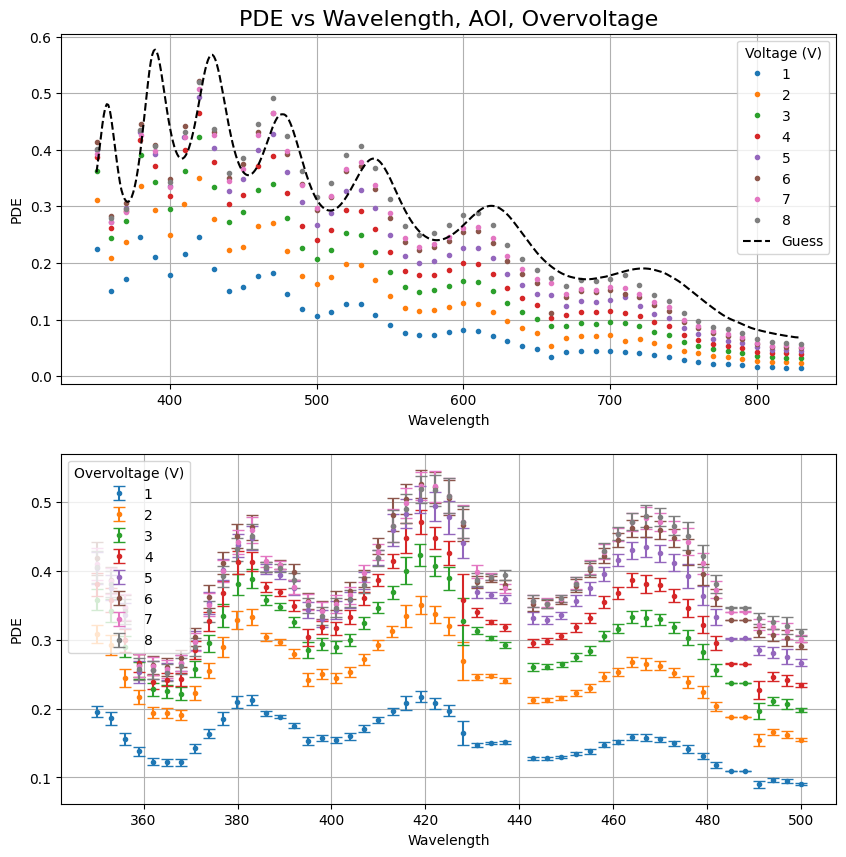

Angles: [1 2 3 4 5 6 7 8]
voltages: [1 2 3 4 5 6 7 8]


In [10]:
## Plot the data
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=False, figsize = (10, 10))

for voltage in data_voltages:
    dt2 = df[(df['Angle'] == 0) & (df['Overvoltage'] == voltage)]
    dt2.plot(x='Wavelength', y = "PDE",label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax1)

# xv4 = df[df['Overvoltage'] == 4]
for voltage in data_voltagesHR:
    dt1 = dfHR[(dfHR['Angle'] == 0) & (dfHR['Overvoltage'] == voltage)]

    dt1.plot(x='Wavelength', y = "PDE", yerr="PDE_error", capsize=4, label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax2)
    

# some guesses
xGuess = np.arange(df['Wavelength'].min(), df['Wavelength'].max(), 1)
test_Boring = {"FF": 0.8, "quantum": False, "smoothSigma": None, "dh":dhAspnes}
testPars = {"tOxide": 1390, "dp_star": 1, "Xpn": 0.3e3, "dw_star": 6e3, "pe": 0.95, "ph": 0.35}
yGuess = PDE_allArgs(wlen=xGuess, theta1=0, **testPars, **test_Boring)

ax1.plot(xGuess, yGuess, label = "Guess", color = "black", linestyle = "--")

ax1.legend(title = "Voltage (V)")
ax1.set_ylabel("PDE")

ax2.legend(title = "Overvoltage (V)")
ax2.set_ylabel("PDE")

ax1.grid(), ax2.grid()
# ax2.set_xlim(380, 420)

ax1.set_title("PDE vs Wavelength, AOI, Overvoltage", fontsize = 16)
# plt.subplots_adjust(hspace=0)
plt.show()
print("Angles:", data_voltages)
print("voltages:", data_voltages)

In [1]:
## Loading in Harry's PE data
file_path_pe = os.path.join(PROPATH, "../veraData/HPK_EHPAIR_183K.csv")
df_pe = pd.read_csv(file_path_pe, header=0)

# print(df_pe)
df_pe=df_pe[df_pe['Wavelength'] == 380]
# print(df_pe)

harryPe = df_pe['normalized rate'].values
harryPedict = {df_pe["Overvoltage"].values[i]: harryPe[i] for i in range(len(harryPe))}
print(harryPedict)

print("---- Harry Pe values ----")
plt.figure(figsize=(4, 2))
plt.plot(df_pe["Overvoltage"], harryPe, marker = "o")
plt.show()

NameError: name 'os' is not defined

---
---
## Parameters shared by everything

In [13]:
FF1 = 0.8
scaleErrors = 0.02 # do 5% errors on PDE
# scaleHarry = 0
ttGood = 1390 # good thickness in nm

fixedPars_Boring = {"FF": FF1, "quantum": False, "smoothSigma": 3.8, "dh":dhAspnes}


---
---
### UV high V Dataset
No nested/nuisance pars are required here  


In [14]:
##-- Buiding A1 dataset --##
UVLim = 380
# dataset 0A
v_0A = data_voltagesHR[-1]
v_0A2 = data_voltagesHR[-3]
angle_0A = data_anglesHR[0]

# temporary datasets
dfA_t1 = dfHR[(dfHR['Overvoltage'] == v_0A) & (dfHR['Angle'] == angle_0A) & (dfHR['Wavelength'] < UVLim)]
dfA2_t2 = dfHR[(dfHR['Overvoltage'] == v_0A2) & (dfHR['Angle'] == angle_0A)& (dfHR['Wavelength'] < UVLim)]

# use LR data for this fit instead
# dfA2_t2 = df[(df['Overvoltage'] == v_0A2) & (df['Angle'] == angle_0A)& (df['Wavelength'] < UVLim)]
# lol three data points in LR data
data_UV_V = [
    # {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error'], "theta1": angle_0A},
    {"wlen":dfA2_t2['Wavelength'], "yVals": dfA2_t2['PDE'], "yErrs": dfA2_t2['PDE_error']*scaleErrors, "theta1": angle_0A}
    ]

print("voltage wanted:", v_0A2, "V")
print("angle wanted:", angle_0A, "deg")
# print("data_UV_V[0]:", data_UV_V[0])

SS.CheckDataSetKey_consistent(data_UV_V, True);

voltage wanted: 6 V
angle wanted: 0 deg
-- CheckDataSetKey_consistent() --
	Dataset(s) have same keys, proceed


---
---
### UV high V Fitting: Permutation A
No nested/nuisance pars are required here  
Global float: 
* float $P_e$, $dp^*$
* $t_{oxide} = 16.5$ nm

In [15]:
# global fixed
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_A_UV = {"tOxide": ttGood, "Xpn": 300, "dw_star":5e3, "ph":0.0, **fixedPars_Boring}

floatPars_A_UV = { "dp_star": 1.0, "pe": 1.0}
floatBounds_A_UV = {"dp_star": (0.1, 14), "pe": (0.7, 1.1)}
# SS.AddNonesToDict(dAddTo=floatBounds_A_UV, dRef=floatPars_A_UV)

print("------ Case AE-UV setup ------")
SS.CheckAllConditions_forResiduals(func=PDE_allArgs, dataObj=data_UV_V, dFixed=fixedPars_A_UV, dFloat=floatPars_A_UV,
                                   dBounds=floatBounds_A_UV, yNames=("yVals", "yErrs"), verbose=False)
xoAE_UV, xoAE_UV_Names = SS.BuildX0(floatDict=floatPars_A_UV, functionToFit=PDE_allArgs)
xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_A_UV, functionToFit=PDE_allArgs)

print("------ Case AE-UV Fit ------")
result_A_UV = iminuit.minimize(SS.GenericResiduals, x0=xoAE_UV, bounds = xABounds, args=(fixedPars_A_UV, data_UV_V, PDE_allArgs), method='migrad')
SS.GenericResiduals(x0=result_A_UV.x, dataObj=data_UV_V, functionToFit=PDE_allArgs, fixedArgs_dict=fixedPars_A_UV, verbose=False, yNames=("yVals", "yErrs"))
# print(result_A_UV)
print("chi2 score-ish:", result_A_UV.fun)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum', 'dh']
------ Case AE-UV setup ------
------ Case AE-UV Fit ------
chi2 score-ish: 327531.8183381244


  message: Optimization terminated successfully.
  success: True
      fun: 327531.8183381244
        x: [ 5.187e+00  1.100e+00]
 hess_inv: ┌────┬─────────────────────────┐
           │    │          x0          x1 │
           ├────┼─────────────────────────┤
           │ x0 │    6.88e-06 -3.8127e-15 │
           │ x1 │ -3.8127e-15    5.53e-19 │
           └────┴─────────────────────────┘
     nfev: 90
     njev: 0
   minuit: ┌─────────────────────────────────────────────────────────────────────────┐
           │                                Migrad                                   │
           ├──────────────────────────────────┬──────────────────────────────────────┤
           │ FCN = 3.275e+05                  │              Nfcn = 90               │
           │ EDM = 2.13e-07 (Goal: 0.0001)    │            time = 0.2 sec            │
           ├──────────────────────────────────┼──────────────────────────────────────┤
           │          Valid Minimum           │   Below ED

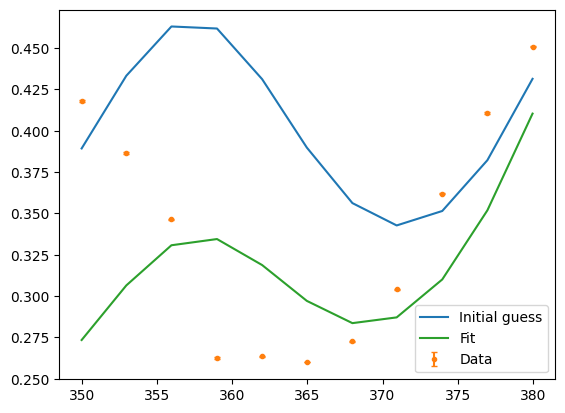

In [16]:

print(result_A_UV)
resDict_A_UV = SS.GetResDict(result_A_UV, xoAE_UV_Names)
resDictErrors_A_UV = SS.GetResErrorDict(result_A_UV, xoAE_UV_Names)
print(resDict_A_UV)
print("errors:", resDictErrors_A_UV)

# correlation matrix
print(SS.GetCorrelationMatrix(result_A_UV.hess_inv))

## plotting ##
# plt.errorbar(x=dataA[0]["wlen"], y=dataA[0]["yVals"], yerr=dataA[0]["yErrs"], label = "Data 8V")
yTest=PDE_allArgs(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **floatPars_A_UV, **fixedPars_A_UV)

plt.plot(data_UV_V[0]["wlen"], yTest, label="Initial guess")
plt.errorbar(data_UV_V[0]["wlen"], data_UV_V[0]["yVals"], yerr=data_UV_V[0]["yErrs"], marker = ".", linestyle="None",capsize= 2, label="Data")

yFit = PDE_allArgs(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **resDict_A_UV, **fixedPars_A_UV)
plt.plot(data_UV_V[0]["wlen"], yFit, label="Fit")

toPlotNarrow = fixedPars_A_UV.copy()
toPlotNarrow['smoothSigma'] = None
yTestNarrow=PDE_allArgs(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **resDict_A_UV, **toPlotNarrow)

plt.legend()
plt.show()

---
---
### UV - __all V__ Datasets
Now $P_e$ is a nuisance parameter (float or fixed)
* __A__: float nested: $P_e$
* __E__: float global: $t_{oxide}$ ??

Will attempt A, C, EC


In [17]:
##-- Buiding A1 dataset --##
# dataset 0A
angle_0A = data_angles[0]
print("data voltages:", data_voltagesHR)

data_UV_all = []
voltageTrackerHR = []
for V in data_voltagesHR:
    voltageTrackerHR.append(V)
    dfA_t1 = dfHR[(dfHR['Overvoltage'] == V) & (dfHR['Angle'] == angle_0A) & (dfHR['Wavelength'] < UVLim)]
    oneD_dict = {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error'], "theta1": angle_0A}
    print(dfA_t1['Overvoltage'].unique(), dfA_t1['PDE'].max())
    data_UV_all.append(oneD_dict)

SS.CheckDataSetKey_consistent(data_UV_all, True);
print("voltages used:", voltageTrackerHR)

data voltages: [1 2 3 4 5 6 7 8]
[1] 0.209849
[2] 0.328741
[3] 0.358051
[4] 0.380258
[5] 0.404364
[6] 0.450742
[7] 0.409544
[8] 0.431397
-- CheckDataSetKey_consistent() --
	Dataset(s) have same keys, proceed
voltages used: [1, 2, 3, 4, 5, 6, 7, 8]


In [18]:
## Building different Nuisance Parameter datasets
data_UVall_A = [] # float Pe
# data_UVall_C = [] # use Harry's fixed Pe

for V, oneD in zip(voltageTrackerHR, data_UV_all):
    
    # nuisFixed_C = {"pe": harryPedict[V]}
    # print("V:", V, "guess pe:", harryPedict[V])
    
    nuisFloat_A = {"pe": harryPedict[V]}
    nuiseFloatBounds_A = {"pe": (0.0, 1.2)}
    
    odFullA = SS.OneNuisanceDataSet(oneDData=oneD, nuisanceFloat=nuisFloat_A, nuisanceBounds=nuiseFloatBounds_A, nuisanceFixed={})
    odFullA.extraV = V
    
    # odFullC = SS.OneNuisanceDataSet(oneDData=oneD, nuisanceFloat={}, nuisanceBounds={}, nuisanceFixed=nuisFixed_C)
    # odFullC.extraV = V
    
    data_UVall_A.append(odFullA)
    # data_UVall_C.append(odFullC)

---
### UV All V Fitting: Permutation A (nested Pe float)

* global float: $dp^*$
* local float: $P_e$
* fixed: $t_{oxide}$

In [19]:
# global fixed
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_global_A = {"Xpn": 0.3e3, "dw_star":10e3, "ph":0., **fixedPars_Boring}

floatPars_global_A = {"tOxide":ttGood, "dp_star": 0.5}
floatBounds_A_UV = {"tOxide":(1000, 2000),  "dp_star": (0.1, 15)}

x0_global_A, x0_global_A_Names = SS.BuildX0(floatDict=floatPars_global_A, functionToFit=PDE_allArgs)
x0_global_A_bounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_A_UV, functionToFit=PDE_allArgs)

print("------ Case A-UVall setup ------")

SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_A, globalFixed=fixedPars_global_A, dataPackage=data_UVall_A,
                               functionToFit=PDE_allArgs, verbose=False)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum', 'dh']
------ Case A-UVall setup ------


1764.5690187397972

In [20]:
globalFit_UVall_A = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_A, bounds = x0_global_A_bounds,
                                     args=(fixedPars_global_A, data_UVall_A, PDE_allArgs), method='migrad')
SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_UVall_A.x, globalFixed=fixedPars_global_A, dataPackage=data_UVall_A,
                               functionToFit=PDE_allArgs, verbose=False)
print("done fit")

done fit


In [21]:
print(globalFit_UVall_A)
resDict_A_UVall = SS.GetResDict(globalFit_UVall_A, x0_global_A_Names)
resErrors_A_UVall = SS.GetResErrorDict(globalFit_UVall_A, x0_global_A_Names)


print("------ Case A-UVall Fit ------")

print("chi2 score-ish:", globalFit_UVall_A.fun)
print(resDict_A_UVall)
print(resErrors_A_UVall)

peVals_A = [dc.resultDict["pe"] for dc in data_UVall_A]
peVals_A_dict = {dc.extraV: dc.resultDict["pe"] for dc in data_UVall_A}
peErrs_A_dict = {dc.extraV: dc.resultErrorsDict["pe"] for dc in data_UVall_A}
print("peVals_A_dict:", peVals_A_dict)
print("peErrs_A_dict:", peErrs_A_dict)

  message: Optimization terminated successfully.
  success: True
      fun: 74.28158394480623
        x: [ 1.359e+03  5.171e-01]
 hess_inv: ┌────┬─────────────┐
           │    │    x0    x1 │
           ├────┼─────────────┤
           │ x0 │  0.48  0.11 │
           │ x1 │  0.11 0.047 │
           └────┴─────────────┘
     nfev: 47
     njev: 0
   minuit: ┌─────────────────────────────────────────────────────────────────────────┐
           │                                Migrad                                   │
           ├──────────────────────────────────┬──────────────────────────────────────┤
           │ FCN = 74.28                      │              Nfcn = 47               │
           │ EDM = 1.79e-05 (Goal: 0.0001)    │           time = 18.3 sec            │
           ├──────────────────────────────────┼──────────────────────────────────────┤
           │          Valid Minimum           │   Below EDM threshold (goal x 10)    │
           ├───────────────────────────────

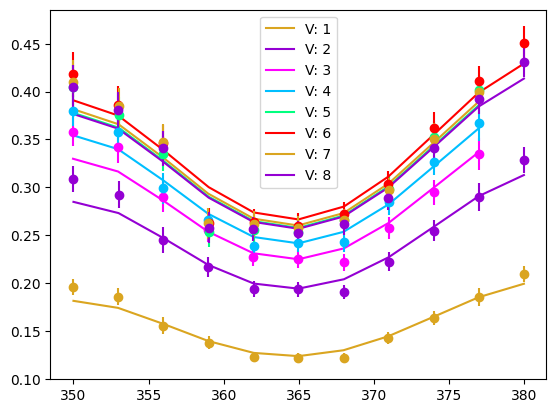

In [22]:
dictA_toPlot = {**resDict_A_UVall, **fixedPars_global_A}
for dc in data_UVall_A:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    # localPE = dc.resultDict["pe"]
    # print(dc.resultDict)
    col = ms.GetNextColor()
    
    yFit = PDE_allArgs(wlen=xwlen, theta1=oneD["theta1"], **dc.resultDict,  **dictA_toPlot)
    plt.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
    plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o")
    
plt.legend()
plt.show()


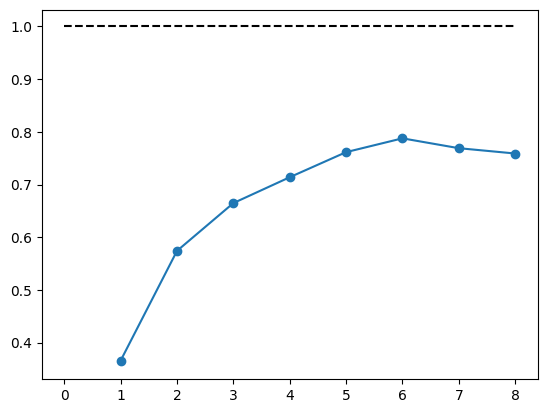

In [23]:
peHarry = np.array([harryPedict[V] for V in voltageTrackerHR])
ype = [peVals_A_dict[V] for V in voltageTrackerHR]
ypeErrs = [peErrs_A_dict[V] for V in voltageTrackerHR]

# print("pe offset:", peVals_A - peHarry)
# print("pe ratio:", 1-peHarry/peVals_A)

plt.errorbar(voltageTrackerHR, ype, yerr=ypeErrs, marker="o", label="Pe A fit")
plt.hlines(1.0, 0, 8, linestyle = "--", color="k")
# plt.plot(voltageTrackerHR, peHarry, marker="o", label="Pe Harry")


# plt.plot(voltageTrackerHR, peVals_A/peHarry, marker="o", label="ratio (this/harry)")
# plt.plot(voltageTrackerHR, peHarry-peVals_A, marker="o", label="pe offset")

# plt.legend()

---
### Fitting Entire Range - Vis
## Standard Vis fit - Permutation __S__

Front of junction is fixed
* fixed (nested/global): $P_e$, $d_p^*$ = values from fit A
* float nested: $P_h$
* float global: $X_{PN}$, $dw^*$

In [24]:
##-- Buiding Vis all dataset --##
angle_0A = data_angles[0]
print(data_voltages)
voltageTracker = data_voltages

data_Vis_allS = []
onlyData_vis_all = []
for V in voltageTracker:
    dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A)]
    tempErrors = dfA_t1['PDE'] * scaleErrors
    oneD_dict = {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": tempErrors, "theta1": angle_0A}
    
    tempFixedPE = peVals_A_dict[V] if V in peVals_A_dict else 1.0
    tempFixedPE = 1.0 if tempFixedPE > 1 else tempFixedPE
    print("V:", V, "guess pe:", tempFixedPE)
    fixedNuisDict = {"pe": tempFixedPE}
    
    floatNuisDict = {"ph": 0.15}
    floatBoundsNuisDict = {"ph": (0.0, 1.1)}
    odFullA = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=floatNuisDict, nuisanceBounds=floatBoundsNuisDict,
                                    nuisanceFixed=fixedNuisDict)
    odFullA.extraV = V
    data_Vis_allS.append(odFullA)
    onlyData_vis_all.append(oneD_dict)

SS.CheckDataSetKey_consistent(onlyData_vis_all, True);
type(data_Vis_allS[0].oneDData);

[1 2 3 4 5 6 7 8]
V: 1 guess pe: 0.3658
V: 2 guess pe: 0.5741
V: 3 guess pe: 0.6648
V: 4 guess pe: 0.7139
V: 5 guess pe: 0.7615
V: 6 guess pe: 0.7877
V: 7 guess pe: 0.769
V: 8 guess pe: 0.7589
-- CheckDataSetKey_consistent() --
	Dataset(s) have same keys, proceed


In [25]:
print("List of args needed:", SS.GetNames(PDE_allArgs))
print("using results from UV_A", resDict_A_UVall)

fixedPars_Vis_S = {"tOxide":ttGood, **resDict_A_UVall, **fixedPars_Boring}
fixedPars_Vis_S["FF"] = FF1
print("\nfixed inputs:", fixedPars_Vis_S)

floatPars_Vis_S = {"Xpn": 0.5e3, "dw_star": 3e3}
floatParBounds_Vis_S = {"Xpn": (0.1e3, 1.5e3), "dw_star": (1.5e3, 10e3)}

x0_global_S, x0_global_S_Names = SS.BuildX0(floatDict=floatPars_Vis_S, functionToFit=PDE_allArgs)
x0_global_S_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_Vis_S, functionToFit=PDE_allArgs)

print("------ Case S - Vis all ------")
SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_S, globalFixed=fixedPars_Vis_S, dataPackage=data_Vis_allS,
                               functionToFit=PDE_allArgs, verbose=False)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum', 'dh']
using results from UV_A {'tOxide': 1359.1701, 'dp_star': 0.5171}

fixed inputs: {'tOxide': 1359.1701, 'dp_star': 0.5171, 'FF': 0.8, 'quantum': False, 'smoothSigma': 3.8, 'dh': <PDEhelpers.OpticsDataLoader.OpticsData object at 0x147c3a190>}
------ Case S - Vis all ------


9208.495999891542

In [26]:
startTime = time.time()
globalFit_Visall_S = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_S, bounds = x0_global_S_bounds,
                                        args=(fixedPars_Vis_S, data_Vis_allS, PDE_allArgs), method='migrad')
SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_Visall_S.x, globalFixed=fixedPars_Vis_S, dataPackage=data_Vis_allS,
                                    functionToFit=PDE_allArgs, verbose=False)
endTime = time.time()
print("Done fit! Time taken:", endTime-startTime)

Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3505, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_52874/1287073569.py", line 2, in <module>
    globalFit_Visall_S = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_S, bounds = x0_global_S_bounds,
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/iminuit/minimize.py", line 118, in minimize
    m.migrad(ncall=ncall)
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/iminuit/minuit.py", line 791, in migrad
    fm = migrad(ncall, self._tolerance)
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Version

In [ ]:
# print(globalFit_Visall_S)
print("score:", globalFit_Visall_S.fun)
resDict_VisAll_S = SS.GetResDict(globalFit_Visall_S, x0_global_S_Names)
resDictError_Visall_S = SS.GetResErrorDict(globalFit_Visall_S, x0_global_S_Names)
print("from UV fit:", resDict_A_UVall)
print("error UV fit:", resErrors_A_UVall)
print("result Dict:", resDict_VisAll_S)
print("result Errors:",resDictError_Visall_S)

phFull_dict_S = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_Vis_allS}
pdFull_dict_forcedS = {dc.extraV: dc.mDict_nuisFixed["pe"] for dc in data_Vis_allS}
peFull_dict_A = {dc.extraV: (dc.resultDict["pe"], dc.resultErrorsDict["pe"]) for dc in data_UVall_A}

print("pe:", peFull_dict_A)
print("ph:", phFull_dict_S)


In [ ]:
dict_visAll_S_final = {**resDict_A_UVall, **resDict_VisAll_S, **fixedPars_Vis_S}
print(dict_visAll_S_final)

otherDict = dict_visAll_S_final.copy()
otherDict["dh"] = dhAspnes

for dc in data_Vis_allS:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    voltage = dc.extraV
    localPe = peFull_dict_A[voltage][0] if voltage in peFull_dict_A else 1.0
    localPh = phFull_dict_S[voltage][0]
    pArgs = {"pe": localPe, **dc.resultDict}
    
    col = ms.GetNextColor()
    
    xPretty = np.arange(min(xwlen), max(xwlen), 1)
    yFit = PDE_allArgs(wlen=xPretty, theta1=oneD["theta1"], **dict_visAll_S_final, **pArgs)
    
    plt.plot(xPretty, yFit, color = col, label=f"V: {dc.extraV}")
    
    # yFit_standard = PDE_allArgs(wlen=xwlen, theta1=oneD["theta1"], **otherDict, **pArgs)
    # plt.plot(xwlen, yFit_standard, color = col, linestyle="--")
    
    plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)

plt.title("sequential fit, vis")
plt.legend()
plt.show()

In [ ]:

yph_visS = [phFull_dict_S[voltage][0] for voltage in voltageTracker]
yphErr_visS = [phFull_dict_S[voltage][1] for voltage in voltageTracker]

ype_UV = [peFull_dict_A[voltage][0] for voltage in voltageTracker]
ypeErr_UV = [peFull_dict_A[voltage][1] for voltage in voltageTracker]

ype_forced = [pdFull_dict_forcedS[voltage] for voltage in voltageTracker]


plt.errorbar(voltageTracker, yph_visS, yphErr_visS, label="ph")
plt.errorbar(voltageTracker, ype_UV, ypeErr_UV, label="pe")

plt.plot(voltageTracker, ype_forced, marker="o", label="pe, enforce 1")

plt.legend()

---
---
## Global fit
Relative to __S__ above, this also float $dp^*$ and floats both $P$ values for each voltage
* float global: $X_{pn}$, $dw^*$, $dp^*$
* nested float: $P_e$, $P_h$

In [ ]:
##-- Buiding Vis all dataset --##
angle_0A = data_angles[0]
print(data_voltages)
voltageTracker = data_voltages

data_global_all = []
onlyData_global_all = []
for V in voltageTracker:
    dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A)]
    tempErrors = dfA_t1['PDE'] * scaleErrors
    oneD_dict = {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": tempErrors, "theta1": angle_0A}
    
    # tempFixedPE = peVals_A_dict[V] if V in peVals_A_dict else 1.0
    tempFixedPE = harryPedict[V] if V in harryPedict else 1.0
    tempFixedPE = 1.0 if tempFixedPE > 1 else tempFixedPE # get rid of +1 values
    print("V:", V, "guess pe:", tempFixedPE)
    fixedNuisDict = {}
    
    floatNuisDict = {"pe": tempFixedPE, "ph": 0.15}
    floatBoundsNuisDict = {"pe": (0.0, 1.1), "ph": (0.0, 1.1)}
    odFullS = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=floatNuisDict, nuisanceBounds=floatBoundsNuisDict,
                                    nuisanceFixed=fixedNuisDict)
    odFullS.extraV = V
    data_global_all.append(odFullS)
    onlyData_global_all.append(oneD_dict)

SS.CheckDataSetKey_consistent(onlyData_global_all, True);
type(data_global_all[0].oneDData);

[1 2 3 4 5 6 7 8]
V: 1 guess pe: 0.486306
V: 2 guess pe: 0.733673
V: 3 guess pe: 0.858569
V: 4 guess pe: 0.925484
V: 5 guess pe: 0.961845
V: 6 guess pe: 0.981696
V: 7 guess pe: 0.993065
V: 8 guess pe: 0.997103
-- CheckDataSetKey_consistent() --
	Dataset(s) have same keys, proceed


In [ ]:
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_Global = {"tOxide":1360, **fixedPars_Boring}

print("\nfixed inputs:", fixedPars_Global)

floatPars_Global = {"dp_star":2.0, "Xpn": 0.4e3, "dw_star": 4e3}
floatParBounds_Global = {"dp_star":(0.1, 5), "Xpn": (0.1e3, 1.5e3), "dw_star": (1.5e3, 10e3)}

x0_global_global, x0_global_global_Names = SS.BuildX0(floatDict=floatPars_Global, functionToFit=PDE_allArgs)
x0_global_global_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_Global, functionToFit=PDE_allArgs)

print("------ Case S - Vis all ------")
SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_global, globalFixed=fixedPars_Global, dataPackage=data_global_all,
                               functionToFit=PDE_allArgs, verbose=False)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum', 'dh']

fixed inputs: {'tOxide': 1360, 'FF': 0.8, 'quantum': False, 'smoothSigma': 3.8, 'dh': <PDEhelpers.OpticsDataLoader.OpticsData object at 0x17f898110>}
------ Case S - Vis all ------


4344.709709686298

In [ ]:
startTime = time.time()
result_globalFit_all = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_global, bounds = x0_global_global_bounds,
                                        args=(fixedPars_Global, data_global_all, PDE_allArgs), method='migrad')
SS.GenericResiduals_Nuisance_1(globalFloat=result_globalFit_all.x, globalFixed=fixedPars_Global, dataPackage=data_global_all,
                                    functionToFit=PDE_allArgs, verbose=False)
endTime = time.time()
print("Done fit! Time taken:", endTime-startTime)

Done fit! Time taken: 76.38574481010437


In [ ]:
# print(globalFit_fullGlobal)
print("score:", result_globalFit_all.fun)
resDict_fullGlobal = SS.GetResDict(result_globalFit_all, x0_global_global_Names)
resDictError_fullGlobal = SS.GetResErrorDict(result_globalFit_all, x0_global_global_Names)
print("global fit:", resDict_fullGlobal)
print("global fit errors:", resDictError_fullGlobal)

peFull_dict_global = {dc.extraV: (dc.resultDict["pe"], dc.resultErrorsDict["pe"]) for dc in data_global_all}
phFull_dict_global = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_global_all}

print("pe:", peFull_dict_global)
print("ph:", phFull_dict_global)


score: 2581.7158212436425
global fit: {'dp_star': 1.1805, 'Xpn': 321.9276, 'dw_star': 4398.8213}
global fit errors: {'dp_star': 0.0506, 'Xpn': 3.6957, 'dw_star': 38.8017}
pe: {1: (0.4112, 0.0015), 2: (0.5967, 0.0022), 3: (0.7185, 0.0026), 4: (0.7922, 0.0029), 5: (0.8397, 0.0031), 6: (0.8866, 0.0033), 7: (0.8564, 0.0032), 8: (0.8791, 0.0033)}
ph: {1: (0.0632, 0.0004), 2: (0.1087, 0.0006), 3: (0.1597, 0.0008), 4: (0.2039, 0.001), 5: (0.2497, 0.0011), 6: (0.2838, 0.0012), 7: (0.3118, 0.0013), 8: (0.352, 0.0014)}


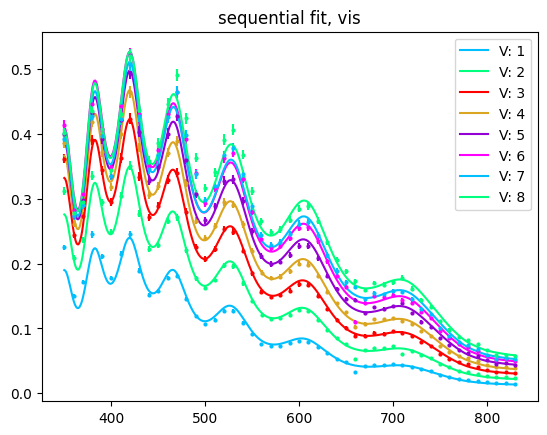

In [ ]:
for dc in data_global_all:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    pAvalanche = dc.resultDict
    
    voltage = dc.extraV
    
    col = ms.GetNextColor()
    
    xPretty = np.arange(min(xwlen), max(xwlen), 1)
    yFit = PDE_allArgs(wlen=xPretty, **fixedPars_Global, theta1=oneD["theta1"], **resDict_fullGlobal, **pAvalanche)
    plt.plot(xPretty, yFit, color = col, label=f"V: {dc.extraV}")
    
    # yFit_standard = PDE_allArgs(wlen=xwlen, theta1=oneD["theta1"], **otherDict, **pArgs)
    # plt.plot(xwlen, yFit_standard, color = col, linestyle="--")
    
    plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)

plt.title("sequential fit, vis")
plt.legend()
plt.show()

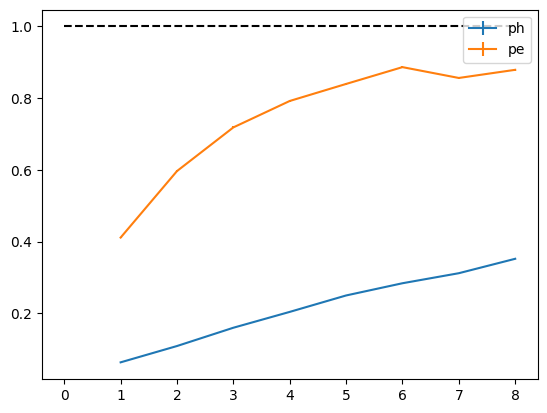

In [ ]:
yph_visS = [phFull_dict_global[voltage][0] for voltage in voltageTracker]
yphErr_visS = [phFull_dict_global[voltage][1] for voltage in voltageTracker]


ype_UV = [peFull_dict_global[voltage][0] for voltage in voltageTracker]
ypeErr_UV = [peFull_dict_global[voltage][1] for voltage in voltageTracker]

plt.errorbar(voltageTracker, yph_visS, yphErr_visS, label="ph")
plt.errorbar(voltageTracker, ype_UV, ypeErr_UV, label="pe")
plt.hlines(1.0, 0, 8, linestyle = "--", color="k")

plt.legend()